# Step 1: Load and Prepare the Red Wine Quality Dataset

Load the UCI Red Wine Quality data, engineer three domain features, create a binary quality target, and save the resulting 14-feature dataset. This step verifies dataset dimensions, missing values, feature names, and target class counts.

In [1]:
import pandas as pd

DATASET_URL = (
    "https://archive.ics.uci.edu/ml/machine-learning-databases/"
    "wine-quality/winequality-red.csv"
)
OUTPUT_PATH = "wine_dataset_cleaned.csv"

df = pd.read_csv(DATASET_URL, sep=";")
df.columns = df.columns.str.replace(" ", "_", regex=False)

df["total_acidity"] = df["fixed_acidity"] + df["volatile_acidity"]
df["bound_sulfur_dioxide"] = (
    df["total_sulfur_dioxide"] - df["free_sulfur_dioxide"]
)
df["sugar_to_acidity_ratio"] = df["residual_sugar"] / (
    df["total_acidity"] + 1e-5
)
df["quality_label"] = (df["quality"] >= 6).astype(int)
df = df.drop(columns=["quality"])

feature_columns = [column for column in df.columns if column != "quality_label"]
df.to_csv(OUTPUT_PATH, index=False)

print(f"Total rows: {len(df)}")
print(f"Total input features: {len(feature_columns)}")
print(f"Missing value count: {int(df.isna().sum().sum())}")
print("Feature names:")
for feature in feature_columns:
    print(f"- {feature}")
print("Target class counts:")
print(df["quality_label"].value_counts().sort_index().to_string())
print(f"Saved cleaned dataset to: {OUTPUT_PATH}")

assert len(df) == 1599, f"Expected 1599 rows, got {len(df)}"
assert len(feature_columns) == 14, (
    f"Expected 14 input features, got {len(feature_columns)}"
)

Total rows: 1599
Total input features: 14
Missing value count: 0
Feature names:
- fixed_acidity
- volatile_acidity
- citric_acid
- residual_sugar
- chlorides
- free_sulfur_dioxide
- total_sulfur_dioxide
- density
- pH
- sulphates
- alcohol
- total_acidity
- bound_sulfur_dioxide
- sugar_to_acidity_ratio
Target class counts:
quality_label
0    744
1    855
Saved cleaned dataset to: wine_dataset_cleaned.csv


## Step 2: Stratified Train/Test Split and Feature Scaling

Separate the 14 input features from `quality_label`, then create a reproducible 80/20 split using stratification so both partitions retain similar class proportions. Export the held-out test features in their original, unscaled form with the target column. Fit `StandardScaler` using only the training features to avoid test-data leakage, and persist the fitted scaler in `model/scaler.pkl` for later application use. No classifier is trained in this step.

In [4]:
from pathlib import Path

import joblib
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
TEST_SIZE = 0.20
TARGET_COLUMN = "quality_label"

feature_columns = [column for column in df.columns if column != TARGET_COLUMN]
X = df[feature_columns]
y = df[TARGET_COLUMN]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y,
)

# Keep the exported test set unscaled for consistent preprocessing in the app.
test_data = X_test.copy()
test_data[TARGET_COLUMN] = y_test
test_data.to_csv("test_data.csv", index=False)

# Fit preprocessing only on training data to prevent test-set leakage.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

model_dir = Path("model")
model_dir.mkdir(parents=True, exist_ok=True)
joblib.dump(scaler, model_dir / "scaler.pkl")

print(f"Training rows: {len(X_train)}")
print(f"Test rows: {len(X_test)}")
print(f"Input features: {len(feature_columns)}")
print("Training target proportions:")
print(y_train.value_counts(normalize=True).sort_index().to_string())
print("Test target proportions:")
print(y_test.value_counts(normalize=True).sort_index().to_string())
print(f"Exported unscaled test data: {test_data.shape}")
print(f"Scaler fitted on training rows only: {scaler.n_samples_seen_ == len(X_train)}")
print(f"Saved scaler: {model_dir / 'scaler.pkl'}")

assert len(X_train) == 1279
assert len(X_test) == 320
assert test_data.columns.tolist() == feature_columns + [TARGET_COLUMN]
assert scaler.n_samples_seen_ == len(X_train)
assert test_data.isna().sum().sum() == 0

Training rows: 1279
Test rows: 320
Input features: 14
Training target proportions:
quality_label
0    0.465207
1    0.534793
Test target proportions:
quality_label
0    0.465625
1    0.534375
Exported unscaled test data: (320, 15)
Scaler fitted on training rows only: True
Saved scaler: model/scaler.pkl


## Step 3: Train and Evaluate the Five Classifiers

Use the same reproducible stratified 80/20 split created in Step 2 and the saved `StandardScaler` fitted on training features. Train Logistic Regression, Decision Tree, K-Nearest Neighbors, Gaussian Naive Bayes, and Support Vector Machine (`probability=True`). Evaluate each model on the held-out test partition using Accuracy, AUC, Precision, Recall, F1, and Matthews Correlation Coefficient (MCC), then save each fitted classifier in the `model/` directory. The test data is used only for evaluation, not for fitting.

In [5]:
import joblib
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    matthews_corrcoef,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.tree import DecisionTreeClassifier

MODEL_DIR = Path("model")
TARGET_COLUMN = "quality_label"
RANDOM_STATE = 42

# Recreate the same split as Step 2 to keep model evaluation reproducible.
X = df[feature_columns]
y = df[TARGET_COLUMN]
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=y,
)

scaler = joblib.load(MODEL_DIR / "scaler.pkl")
assert list(scaler.feature_names_in_) == feature_columns
X_train_scaled = scaler.transform(X_train)
X_test_scaled = scaler.transform(X_test)

models = {
    "Logistic Regression": (
        "logistic_regression.pkl",
        LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    ),
    "Decision Tree": (
        "decision_tree.pkl",
        DecisionTreeClassifier(random_state=RANDOM_STATE),
    ),
    "KNN": ("knn.pkl", KNeighborsClassifier()),
    "Naive Bayes": ("naive_bayes.pkl", GaussianNB()),
    "Support Vector Machine": (
        "svm.pkl",
        SVC(probability=True, random_state=RANDOM_STATE),
    ),
}

metric_rows = []
MODEL_DIR.mkdir(parents=True, exist_ok=True)
for model_name, (filename, model) in models.items():
    model.fit(X_train_scaled, y_train)
    predictions = model.predict(X_test_scaled)
    positive_probabilities = model.predict_proba(X_test_scaled)[:, 1]
    metric_rows.append(
        {
            "ML Model Name": model_name,
            "Accuracy": accuracy_score(y_test, predictions),
            "AUC": roc_auc_score(y_test, positive_probabilities),
            "Precision": precision_score(y_test, predictions, zero_division=0),
            "Recall": recall_score(y_test, predictions, zero_division=0),
            "F1": f1_score(y_test, predictions, zero_division=0),
            "MCC": matthews_corrcoef(y_test, predictions),
        }
    )
    joblib.dump(model, MODEL_DIR / filename)
    print(f"Saved {model_name}: {MODEL_DIR / filename}")

metrics_df = pd.DataFrame(metric_rows)
print("\nHeld-out test metrics:")
print(metrics_df.round(4).to_string(index=False))

assert len(metric_rows) == 5
assert metrics_df.iloc[:, 1:].notna().all().all()

Saved Logistic Regression: model/logistic_regression.pkl
Saved Decision Tree: model/decision_tree.pkl
Saved KNN: model/knn.pkl
Saved Naive Bayes: model/naive_bayes.pkl
Saved Support Vector Machine: model/svm.pkl

Held-out test metrics:
         ML Model Name  Accuracy    AUC  Precision  Recall     F1    MCC
   Logistic Regression    0.7438 0.8239     0.7730  0.7368 0.7545 0.4874
         Decision Tree    0.7531 0.7509     0.7614  0.7836 0.7723 0.5031
                   KNN    0.7438 0.8144     0.7697  0.7427 0.7560 0.4867
           Naive Bayes    0.7125 0.7733     0.7484  0.6959 0.7212 0.4264
Support Vector Machine    0.7406 0.8373     0.7857  0.7076 0.7446 0.4853


## Step 4: Confusion Matrices and ROC Curves

Visualize the held-out test results for all five trained models. The confusion-matrix grid summarizes correct and incorrect class predictions for each classifier. The combined ROC plot compares their true-positive and false-positive rates across decision thresholds, with each model's AUC shown in the legend. These plots complement the numerical metrics from Step 3.

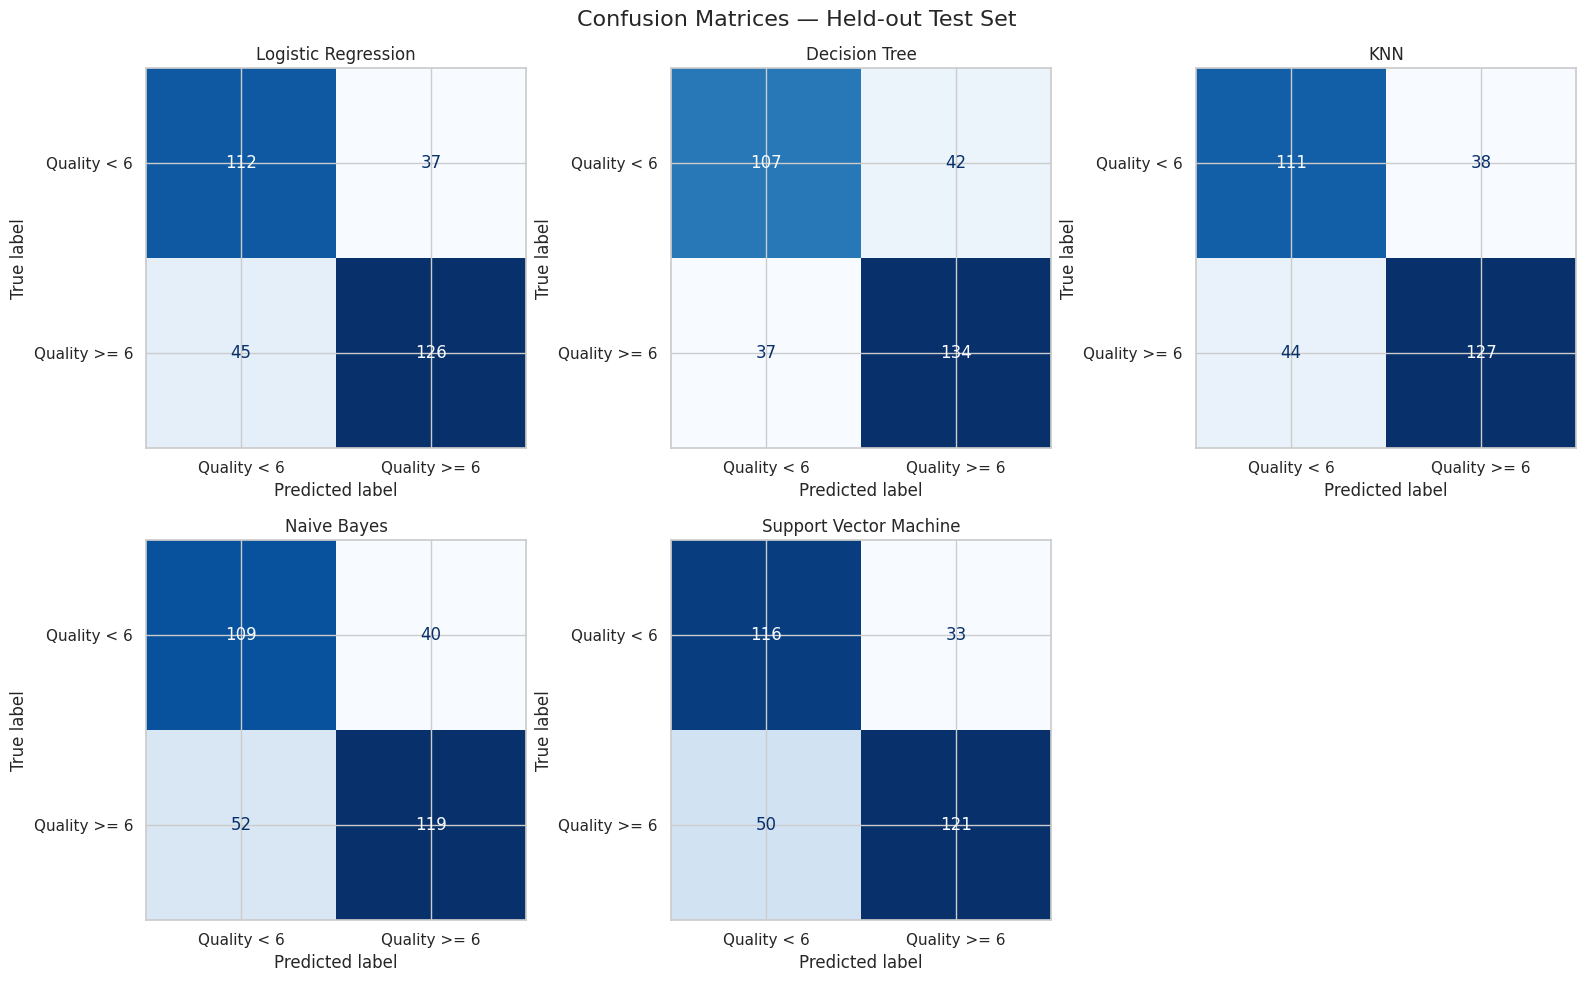

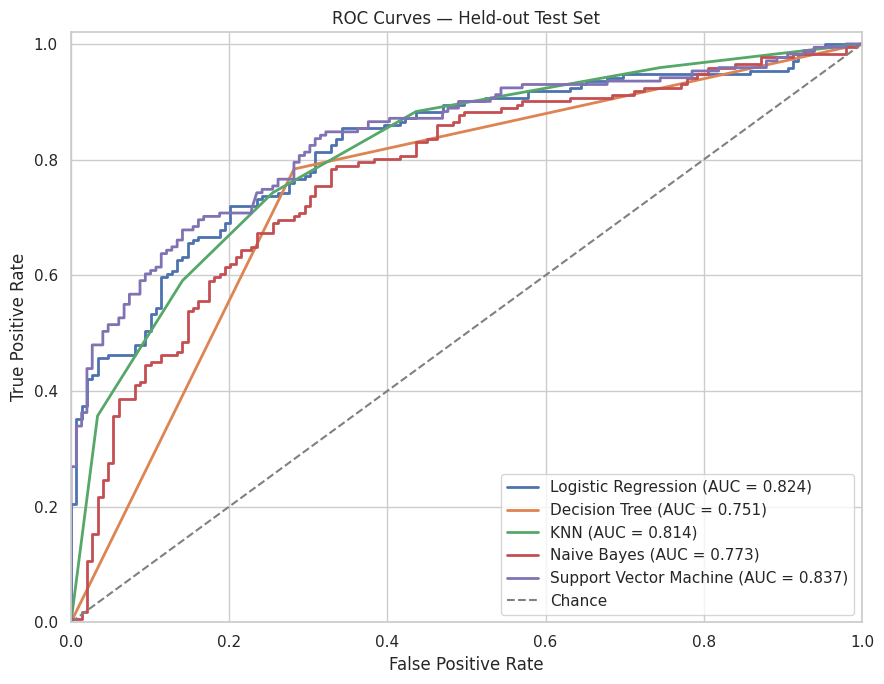

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import ConfusionMatrixDisplay, roc_auc_score, roc_curve

sns.set_theme(style="whitegrid", context="notebook")

fig, axes = plt.subplots(2, 3, figsize=(16, 10))
for axis, (model_name, (_, trained_model)) in zip(axes.flat, models.items()):
    predictions = trained_model.predict(X_test_scaled)
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        predictions,
        display_labels=["Quality < 6", "Quality >= 6"],
        cmap="Blues",
        colorbar=False,
        ax=axis,
    )
    axis.set_title(model_name)

axes.flat[-1].set_visible(False)
fig.suptitle("Confusion Matrices — Held-out Test Set", fontsize=16)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 7))
for model_name, (_, trained_model) in models.items():
    positive_probabilities = trained_model.predict_proba(X_test_scaled)[:, 1]
    false_positive_rate, true_positive_rate, _ = roc_curve(
        y_test, positive_probabilities
    )
    model_auc = roc_auc_score(y_test, positive_probabilities)
    ax.plot(
        false_positive_rate,
        true_positive_rate,
        linewidth=2,
        label=f"{model_name} (AUC = {model_auc:.3f})",
    )

ax.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Chance")
ax.set(
    title="ROC Curves — Held-out Test Set",
    xlabel="False Positive Rate",
    ylabel="True Positive Rate",
    xlim=(0, 1),
    ylim=(0, 1.02),
)
ax.legend(loc="lower right")
fig.tight_layout()
plt.show()